# Hypothesis for Pain experiment

Cheat Sheet Q1

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats 

Load data from ./pain_experiment.csv

In [12]:
df = pd.read_csv("./pain_experiment.csv")
df.head()

,Group,Response
0,Placebo,3
1,Placebo,-1
2,Placebo,2
3,Placebo,3
4,Placebo,-2


## Split Dataset into Placebo vs Drug

In [13]:
placebo = df["Group"] == "Placebo"
drug = df["Group"] == "Drug"

placebo_df = df[placebo]
drug_df = df[drug]

In [14]:
placebo_df.head()

,Group,Response
0,Placebo,3
1,Placebo,-1
2,Placebo,2
3,Placebo,3
4,Placebo,-2


In [15]:
drug_df.head()

,Group,Response
12,Drug,0
13,Drug,2
14,Drug,3
15,Drug,3
16,Drug,-2


For the distribution to be considered normal, the following assumptions must hold true:
1. Scale of Measurement: The variable is continuous and measured on an interval or ratio scale.(True??, Can the group response be considered continuous? I believe its discrete assuming the rating is on a scale of 1 to 10.).
2. Random Sampling: The data are obtained through random and independent sampling. (We can't test this, we assume it to be true)
3. Normality: The data comes from a normal distribution (using the Shaprio-Wilks statisical test, we can test if this is true).
4. Independence: Observations within the sample are independent of each other. (True, in this dataset, we haven't measured the FSIQ for an individual multiple times, each row is a unique, independent observation).

If any of these assumptions fail, then we will have to use the non-normally distributed version of the test:

- $H_{0}: \eta = \eta_0$
- $H_{1}: \eta \neq \eta_0$

## Measuring Normality - Assumption 3

I need to check if each group of data is normally distributed, as such I will run a <u>Shaprio-Wilk</u> normality test on both groups of data.

In the Shapiro-Wilk test, the null and alternative hypothesis is as follows:

- $H_0:$: *The data are normally distributed* (Everything is normal)
- $H_1:$: *The data are NOT normally distributed* (Something significant is going on)

The $\alpha$ value is 5%. α stands for significance level.
So if $p < 0.05$ then we reject the null hypothesis.

In [16]:
placebo_norm = stats.shapiro(placebo_df["Response"])
drug_norm = stats.shapiro(drug_df["Response"])

print(f"Placebo Data (Normality Test): \n{placebo_norm}\n")
print(f"Drug Data (Normality Test): \n{drug_norm}\n")

Placebo Data (Normality Test): 
ShapiroResult(statistic=np.float64(0.9508933607445129), pvalue=np.float64(0.6500808112587905))

Drug Data (Normality Test): 
ShapiroResult(statistic=np.float64(0.8531059381549773), pvalue=np.float64(0.015141108083580115))



Therefore, for the Placebo group, since pvalue (0.65) > 0.05, we do not reject the null hypothesis.
For the Drug group, since pvalue (0.015) < 0.05, we reject the null hypothesis.

Since, one of the group rejects the null hypothesis, we use a non-normal test.

### Hypthesis Test

Since positive values indicate less pain, and negative values indicate increased pain.

Question: Are there significant differences between the pain experienced by the subjects in the two groups?

- H0: There is no difference between the placebo group and drug group.
- H1: There is significant difference between the placebo group and drug group.

Since there are two independent variables, we use the Wilcoxon Mann-Whitney test.





In [17]:
stats.mannwhitneyu(placebo_df["Response"], drug_df["Response"], alternative="two-sided")

MannwhitneyuResult(statistic=np.float64(67.0), pvalue=np.float64(0.17832628313765575))

Since, the p value (0.17) > 0.05, we fail to reject the null hypthesis.
In simple terms, there's no difference between the placebo group and the drug group. We can visualize this with a plotbox.

Response    Axes(0.125,0.11;0.775x0.77)
dtype: object

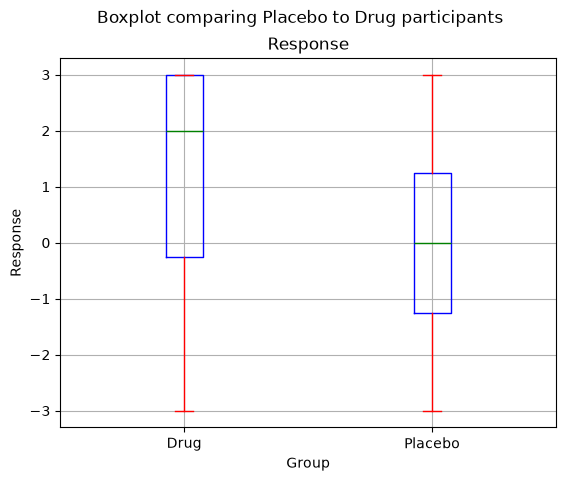

In [18]:
df.plot(kind="box", by="Group", column="Response", 
        color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
        title="Boxplot comparing Placebo to Drug participants",
        ylabel="Response",
        xlabel="Group",
        grid=True)

Group
Drug       Axes(0.125,0.11;0.775x0.77)
Placebo    Axes(0.125,0.11;0.775x0.77)
Name: Response, dtype: object

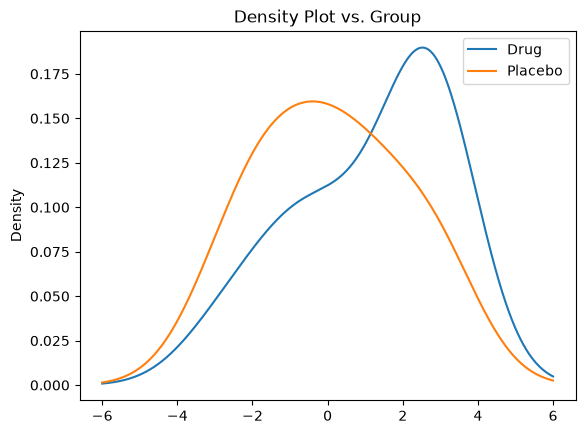

In [19]:
df.groupby("Group")["Response"].plot.kde(title="Density Plot vs. Group",
                                   ylabel="Density",
                                   xlabel="Response",
                                   legend=["Placebo", "Drug"])

<Axes: title={'center': 'Response'}, xlabel='Group', ylabel='Response'>

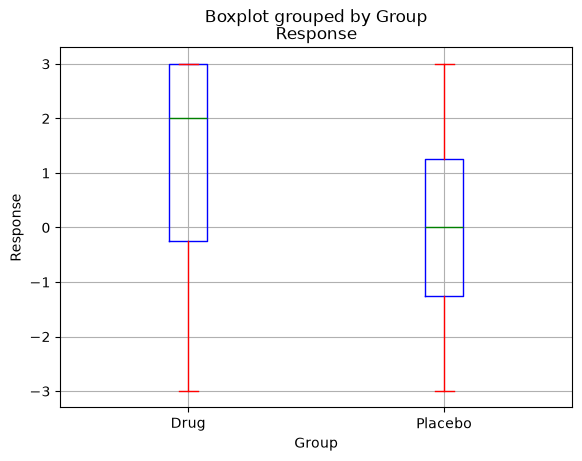

In [20]:
df.boxplot(by="Group", column="Response",
            color=dict(boxes='b', whiskers='r', medians='g', caps='r'),
            ylabel="Response",
)

# Hypothesis for Eye Experiments